# rendeer — executable visual acceptance notebook

This notebook tests the local `rendeer` package (a standalone checkout or `3rd_party/Rendeer`) and displays genuine rendered figures. **All values are synthetic demonstrations, not experimental findings.** The fixed seed is `20261013`. PNG files, manifests and test logs go to scratch; only this requested notebook is retained in the checkout.

Select the uv environment in which you installed `rendeer[dev]`, then run all cells. In the original workspace this is `/scratch/mingyan_root/mingyan/jmtang/env/rendeer-dev/bin/python`. On another machine, set `RENDEER_SCRATCH_ROOT` to your writable scratch directory before starting Jupyter; outputs stay under its `outputs/` directory. No service, model, GPU or network connection is needed. Source changes are picked up in a fresh kernel.

Acceptance: every gallery figure has no detected severe defects; deliberate bad input/layout is rejected; the package test suite exits successfully. Warnings and detection limits remain visible.

In [1]:
from pathlib import Path
import os
import sys

PACKAGE = next(
    candidate.resolve()
    for parent in [Path.cwd(), *Path.cwd().parents]
    for candidate in [parent, parent / "3rd_party" / "Rendeer"]
    if (candidate / "src" / "rendeer" / "__init__.py").is_file()
    and (candidate / "pyproject.toml").is_file()
)
SCRATCH = Path(os.environ.get(
    "RENDEER_SCRATCH_ROOT", "/scratch/mingyan_root/mingyan/jmtang"
)).expanduser().resolve()
OUTPUT = Path(os.environ.get(
    "RENDEER_NOTEBOOK_OUTPUT",
    str(SCRATCH / "outputs/LLM4Policy/synthetic/rendeer/notebook")
)).expanduser().resolve()
assert OUTPUT.is_relative_to(SCRATCH / "outputs"), "Notebook outputs must stay on scratch"
OUTPUT.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(OUTPUT / "cache/matplotlib")
os.environ["RENDEER_TEST_OUTPUT"] = str(OUTPUT / "tests")
os.environ["PYTHONDONTWRITEBYTECODE"] = "1"
sys.dont_write_bytecode = True
for folder in [PACKAGE / "src", PACKAGE / "examples"]:
    sys.path.insert(0, str(folder))

import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib as mpl
from IPython.display import HTML, display
from PIL import Image

before_import = dict(mpl.rcParams)
import rendeer as rd
from gallery import synthetic_data, composite, make_gallery

assert dict(mpl.rcParams) == before_import
rd.configure(theme="paper", palette="default", strict=True, colors=rd.Config().colors)
print(f"Python: {sys.version.split()[0]} | rendeer: {rd.__version__} | Matplotlib: {mpl.__version__}")
print(f"Package: {Path(rd.__file__).resolve()}")
print(f"Output: {OUTPUT}")


Python: 3.12.15 | rendeer: 0.1.0 | Matplotlib: 3.10.8
Package: /home/jmtang/Projects/LLM4Policy/3rd_party/Rendeer/src/rendeer/__init__.py
Output: /scratch/mingyan_root/mingyan/jmtang/outputs/LLM4Policy/synthetic/rendeer/saturation-refresh/notebook


## Default paper palette

Restrained blue, coral and teal identify Ours, Baseline and Ablation. Lavender, ochre, rose and slate extend the categorical cycle. These are custom defaults for white-background ML figures, not an official NeurIPS/ICLR palette. Method markers and line styles remain distinct; uncertainty bands reuse each method color with transparency.

The table screens opaque swatches against white at 3:1. It is not an accessibility certification for translucent fills, overlapping marks, grayscale or all forms of color-vision deficiency.


In [2]:
palette_names = ["Blue", "Coral", "Teal", "Lavender", "Ochre", "Rose", "Slate"]
palette_rows = []
for name, color in zip(palette_names, rd.PALETTES["default"]):
    ratio = rd.contrast_ratio(color, "white")
    palette_rows.append({"name": name, "hex": color, "contrast_on_white": ratio})
    assert ratio >= 3, (name, ratio)
display(HTML(
    '<div style="display:flex;flex-wrap:wrap;gap:14px;margin:12px 0">'
    + "".join(
        f'<div style="width:100px"><div style="height:42px;border-radius:6px;'
        f'background:{row["hex"]}"></div><div style="margin-top:6px">{row["name"]}</div>'
        f'<code>{row["hex"]}</code><div>{row["contrast_on_white"]:.2f}:1</div></div>'
        for row in palette_rows
    ) + '</div>'
))
print("Default method colors:", {name: rd.color_for(name) for name in ["Ours", "Baseline", "Ablation"]})


Default method colors: {'Ours': '#4678ae', 'Baseline': '#d8765a', 'Ablation': '#4aa292'}


## 1. Inspect the synthetic inputs

Five independent synthetic seeds per method, measured at 13 training steps. The generator explicitly defines the curve and noise; it never represents results from LLM4Policy. Repeated steps from the same seed are not counted as extra independent replicates.

In [3]:
data = synthetic_data()
display(data["curves"].head(8))
display(data["benchmark"].pivot(index="task", columns="method", values="f1"))
assert data["curves"].groupby(["method", "step"])["seed"].nunique().eq(5).all()


,step,accuracy,method,seed
0,0,0.479087,Ours,0
1,10,0.574429,Ours,0
2,20,0.657910,Ours,0
3,30,0.709594,Ours,0
4,40,0.754657,Ours,0
5,50,0.787966,Ours,0
6,60,0.803975,Ours,0
7,70,0.835801,Ours,0


method,Ablation,Baseline,Ours
task,,,
Task A,0.80,0.76,0.85
Task B,0.73,0.70,0.78
Task C,0.86,0.83,0.90


## 2. A research figure in four native panels

(a) Mean accuracy ± one sample SD over five independent synthetic seeds. (b) Illustrative benchmark scores, zero-based bars. (c) An illustrative ablation comparison. (d) All measured compute–accuracy points with the nondominated frontier; connecting segments are guides, not interpolated measurements. Methods keep their semantic colors across panels.

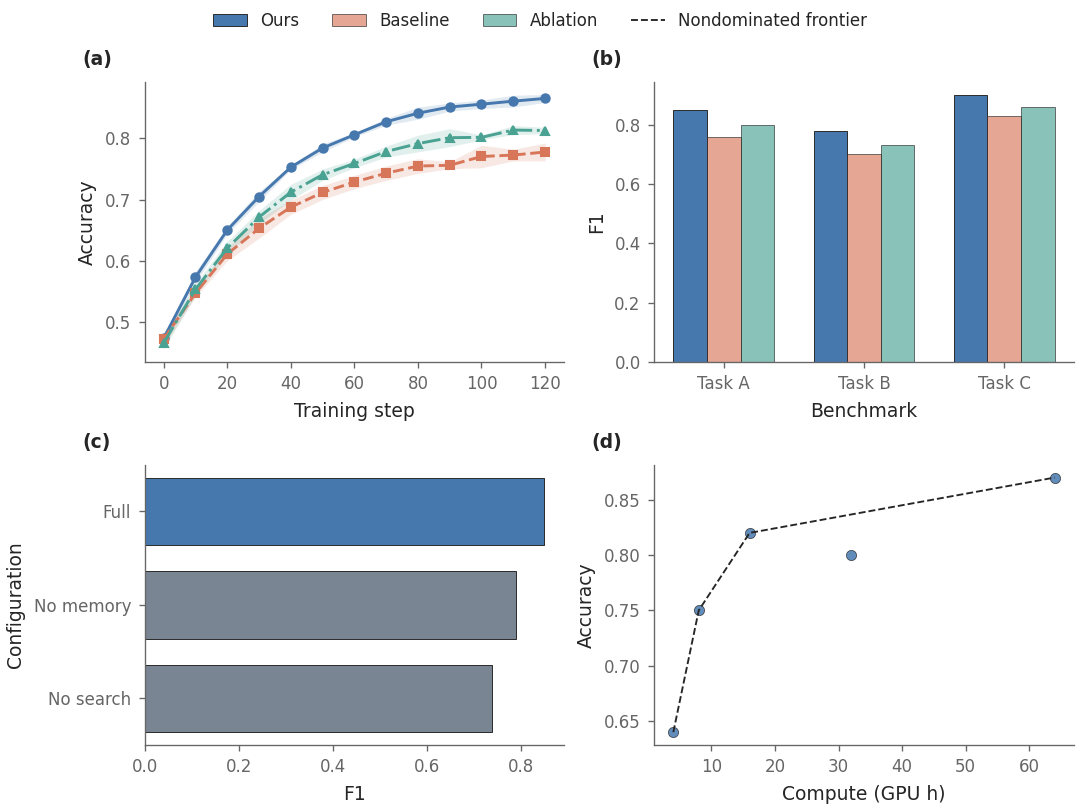

,code,message,panel
0,ambiguous_colors,"Shared color for ['Observed', 'Full']; assign ...",c
1,ambiguous_colors,"Shared color for ['No memory', 'No search']; a...",c


In [4]:
overview = composite(data)
overview_report = overview.validate()
assert overview_report.passed, overview_report.to_dict()
overview.save(OUTPUT / "research_overview.png", overwrite=True)
display(overview)
display(pd.DataFrame([vars(w) for w in overview_report.warnings]))


## 3. Explicit uncertainty and data integrity

`ci95` is a pointwise Student-t interval for the mean of independent, approximately normal seed-level values. It is not SD, SE, a bootstrap interval, or a simultaneous confidence band. The table exposes sample counts and missingness.

,step,method,estimate,lower,upper,n,missing
0,0,Ours,0.473016,0.466833,0.479199,5,0
1,10,Ours,0.572888,0.561523,0.584254,5,0
2,20,Ours,0.650054,0.642518,0.657590,5,0
3,30,Ours,0.704778,0.694596,0.714961,5,0
4,40,Ours,0.752884,0.748668,0.757101,5,0


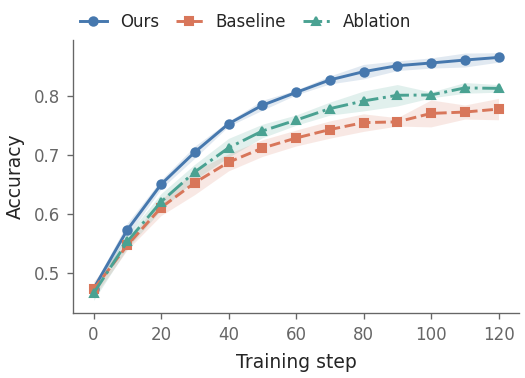

Expected rejection: duplicate x within a series; use error with an independent unit or pre-aggregate


In [5]:
summary = rd.summarize(
    data["curves"], x="step", y="accuracy", hue="method", unit="seed", error="ci95"
)
display(summary.head())
learning = rd.line(
    data["curves"], x="step", y="accuracy", hue="method", unit="seed", error="ci95",
    xlabel="Training step", ylabel="Accuracy"
)
display(learning)
try:
    rd.line(x=[0, 0], y=[0.7, 0.8])
except ValueError as error:
    print("Expected rejection:", error)
else:
    raise AssertionError("Duplicate x was silently accepted")


## 4. Comparison primitives

(a) Raw points, (b) supplied illustrative ranges (not estimated confidence intervals), (c) memory observations filled to zero, and (d) complete stacked components. Native artists remain available for customization.

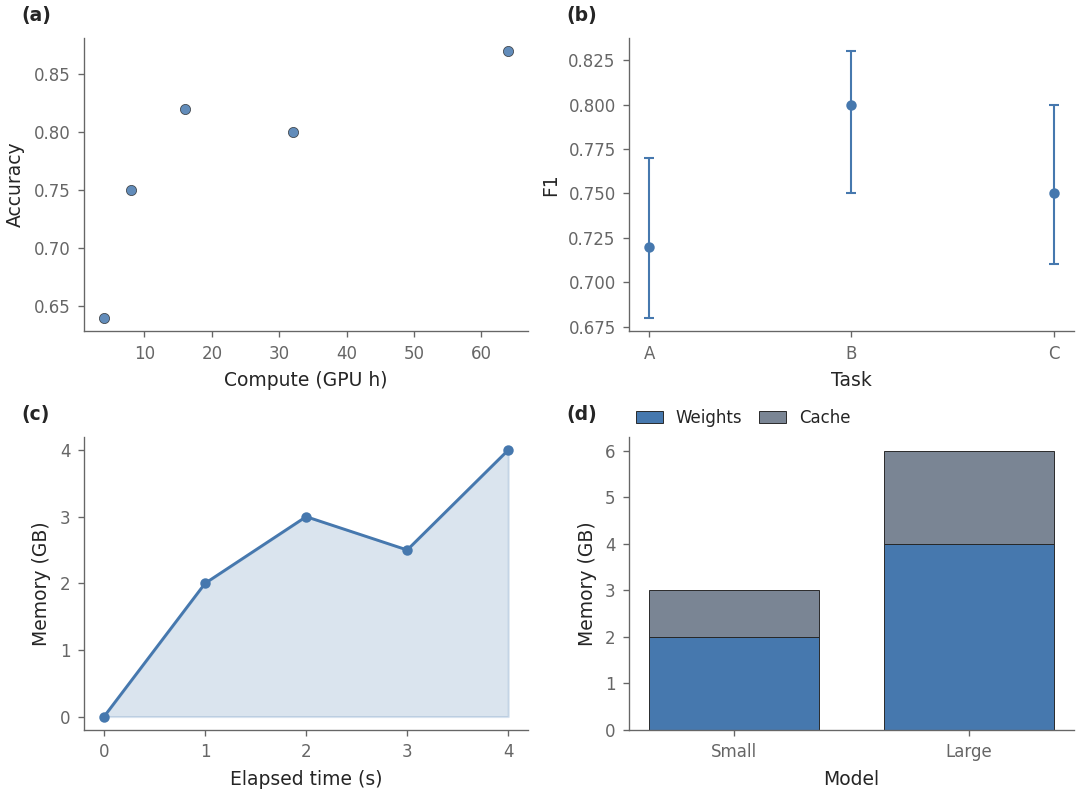

In [6]:
comparison = rd.figure(layout=[["a", "b"], ["c", "d"]], width="double", height=5.3, panel_labels=True)
comparison["a"].scatter(data["tradeoff"], x="compute", y="accuracy",
                         xlabel="Compute (GPU h)", ylabel="Accuracy")
comparison["b"].interval(x=["A", "B", "C"], y=[0.72, 0.8, 0.75],
                          lower=[0.68, 0.75, 0.71], upper=[0.77, 0.83, 0.8],
                          uncertainty="Illustrative supplied range", xlabel="Task", ylabel="F1")
comparison["c"].area(x=[0, 1, 2, 3, 4], y=[0, 2, 3, 2.5, 4],
                      xlabel="Elapsed time (s)", ylabel="Memory (GB)")
parts = pd.DataFrame({"model": ["Small", "Large"] * 2, "GB": [2, 4, 1, 2],
                      "component": ["Weights", "Weights", "Cache", "Cache"]})
comparison["d"].bar(parts, x="model", y="GB", hue="component", stacked=True,
                     xlabel="Model", ylabel="Memory (GB)")
assert comparison.validate().passed
display(comparison)


## 5. Distribution comparisons

(a) Shared-bin histograms, (b) Gaussian KDE with Scott bandwidth, (c) horizontal Tukey boxes retaining outliers, (d) exact ECDF. KDE is explicitly a smoothed density estimate and is clipped to observed support; the ECDF is unsmoothed. Input rows are observations, not inferred independent experiments.

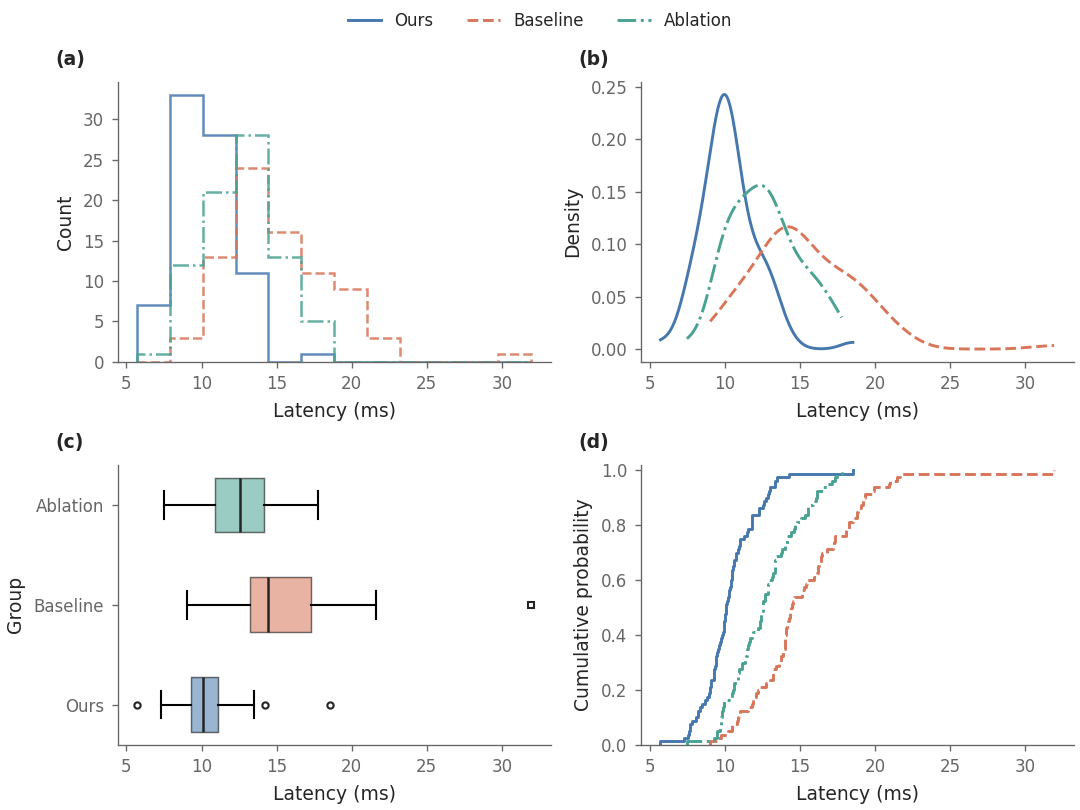

In [7]:
dist = rd.figure(layout=[["a", "b"], ["c", "d"]], width="double", height=5.4, panel_labels=True)
options = dict(data=data["distribution"], x="latency", hue="method", xlabel="Latency (ms)")
dist["a"].hist(**options, bins=12)
dist["b"].kde(**options)
dist["c"].box(**options)
dist["d"].ecdf(**options)
dist.legend()
assert dist.validate().passed
display(dist)


## 6. Matrix semantics

(a) Hyperparameter response with one unobserved cell shown in gray, (b) row-normalized confusion counts. Numeric cell labels choose a contrasting foreground. The colorbars state what the color means.

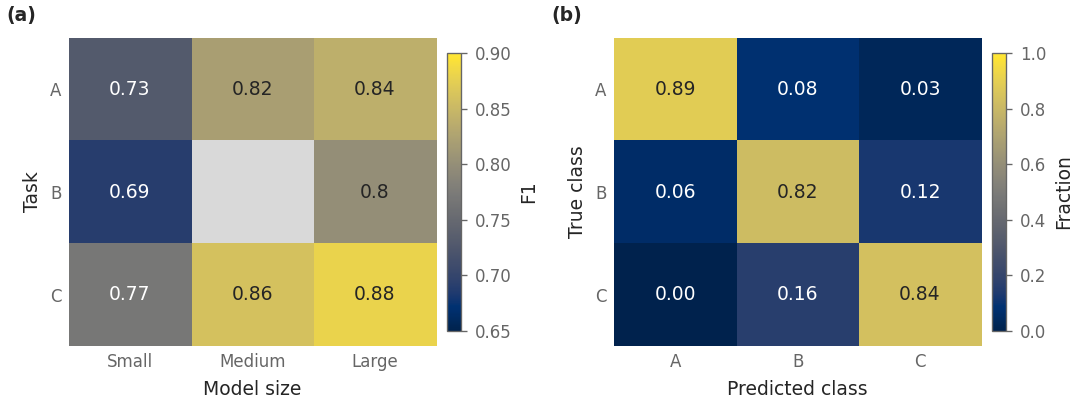

In [8]:
matrix = rd.figure(layout=[["a", "b"]], width="double", height=2.7, panel_labels=True)
matrix["a"].heatmap([[0.73, 0.82, 0.84], [0.69, np.nan, 0.80], [0.77, 0.86, 0.88]],
                     xticklabels=["Small", "Medium", "Large"], yticklabels=["A", "B", "C"],
                     xlabel="Model size", ylabel="Task", cbar_label="F1", annot=True, vmin=0.65, vmax=0.9)
matrix["b"].confusion([[32, 3, 1], [2, 27, 4], [0, 5, 26]], labels=["A", "B", "C"], normalize="true")
assert np.ma.getmaskarray(matrix["a"].ax.images[0].get_array())[1, 1]
assert matrix.validate().passed
display(matrix)


## 7. ML evaluation

(a) ROC and chance diagonal, (b) precision–recall with prevalence reference, (c) reliability diagram using each bin's mean prediction, (d) observed performance–compute frontier. Tied prediction scores are treated as a single threshold. Calibration bins report their counts; no uncertainty bars are invented.

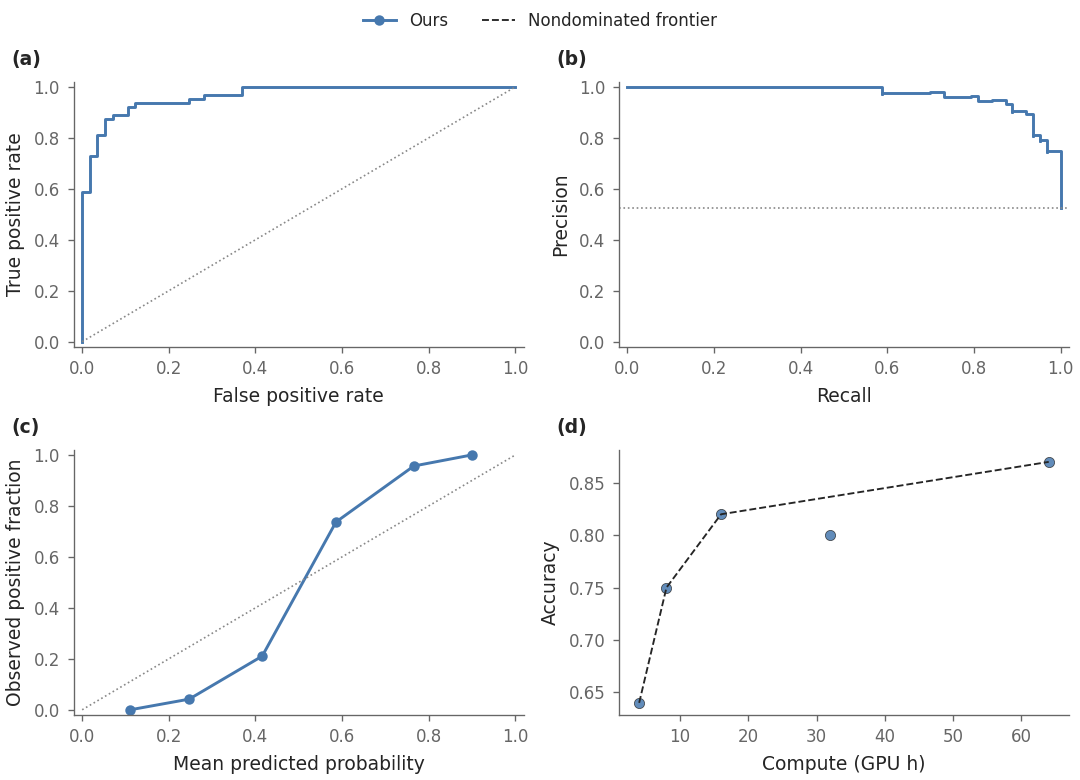

Calibration counts: [13, 24, 19, 19, 23, 22]


In [9]:
evaluation = rd.figure(layout=[["a", "b"], ["c", "d"]], width="double", height=5.2, panel_labels=True)
evaluation["a"].roc(y_true=data["truth"], y_score=data["scores"])
evaluation["b"].precision_recall(y_true=data["truth"], y_score=data["scores"])
evaluation["c"].calibration(y_true=data["truth"], y_prob=data["scores"], bins=6)
evaluation["d"].pareto(data["tradeoff"], x="compute", y="accuracy",
                        xlabel="Compute (GPU h)", ylabel="Accuracy")
evaluation.legend()
assert evaluation.validate().passed
display(evaluation)
print("Calibration counts:", next(r["counts"] for r in evaluation.records if r["kind"] == "calibration"))


## 8. Missing values, long labels and publication presets

The missing observation remains a visible line gap. Long category labels rotate rather than shrink. Nature and grayscale presets are starting points, not publisher or accessibility certifications.

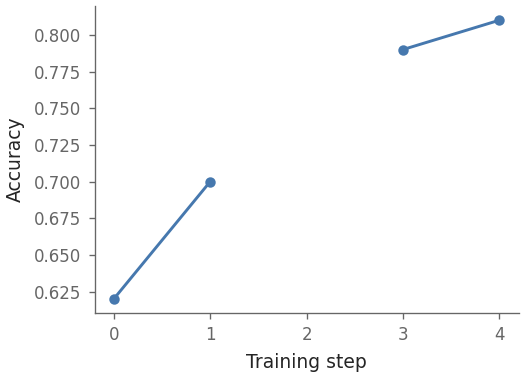

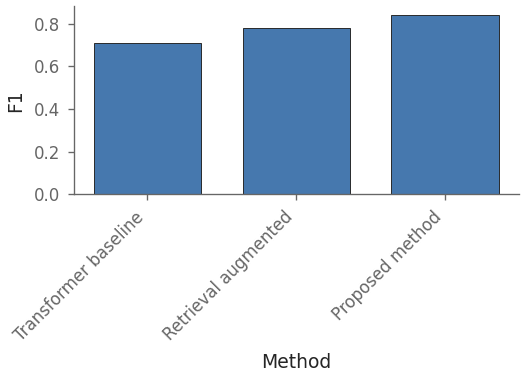

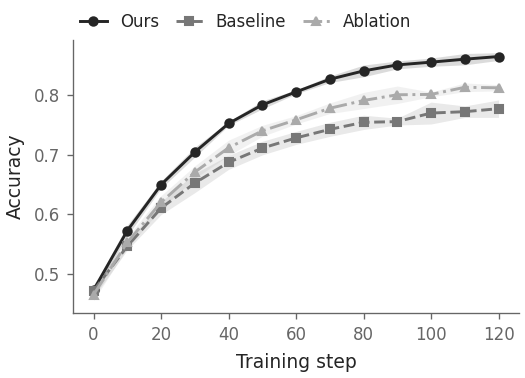

Nature width (mm): 89.0


In [10]:
gap = rd.line(x=[0, 1, 2, 3, 4], y=[0.62, 0.7, np.nan, 0.79, 0.81],
              xlabel="Training step", ylabel="Accuracy")
assert np.isnan(gap.ax.lines[0].get_ydata()[2])
display(gap)
long_labels = rd.bar(x=["Transformer baseline", "Retrieval augmented", "Proposed method"],
                     y=[0.71, 0.78, 0.84], xlabel="Method", ylabel="F1")
assert long_labels.validate().passed
display(long_labels)
with rd.context(theme="grayscale"):
    gray = rd.line(data["curves"], x="step", y="accuracy", hue="method",
                   unit="seed", error="sd", xlabel="Training step", ylabel="Accuracy")
display(gray)
with rd.context(theme="nature"):
    nature = rd.line(x=[0, 1, 2], y=[0.62, 0.72, 0.81], xlabel="Step", ylabel="Accuracy")
assert np.isclose(nature.mpl.get_figwidth(), 89 / 25.4)
assert nature.validate().passed
print("Nature width (mm):", nature.mpl.get_figwidth() * 25.4)


## 9. Strict quality checks must fail on a defective figure

The two text labels below are deliberately coincident. The structured report must identify their overlap, and strict export must fail before writing. Automatic checks do not establish absence of all arbitrary-artist occlusion, missing glyphs, or scientific errors.

In [11]:
bad = rd.scatter(x=[0, 1], y=[0, 1], xlabel="X", ylabel="Y")
bad.ax.text(0.4, 0.5, "Overlapping annotation one")
bad.ax.text(0.4, 0.5, "Overlapping annotation two")
report = bad.validate()
display(pd.DataFrame([vars(issue) for issue in report.errors]))
assert not report.passed and any(issue.code == "text_overlap" for issue in report.errors)
try:
    bad.save(OUTPUT / "must_not_be_written.png", overwrite=True)
except rd.QualityError:
    print("PASS: strict export rejected the defective figure.")
else:
    raise AssertionError("Strict export accepted a defective figure")
assert not (OUTPUT / "must_not_be_written.png").exists()
print(report.coverage)


,code,message,panel
0,text_overlap,'Overlapping annotation one' overlaps 'Overlap...,a


PASS: strict export rejected the defective figure.
Rendered text bounding boxes, axes labels, font sizes, limits, zero baselines, registered semantic colors, and legend bounds. Arbitrary artist occlusion, glyph availability, color-vision accessibility and scientific validity need human review.


## 10. Complete executable gallery and export manifests

Every supported primitive has a real example. The additional examples cover ablation/ranking, stacked bars, missing data, long labels, log/symlog axes, time series, grayscale, many categories and shared colorbars. Each image is saved at 300 DPI with a provenance sidecar. Warning counts remain visible; zero severe errors does not mean zero limitations.

,example,passed,warnings
0,line,True,0
1,scatter,True,0
2,bar,True,0
3,interval,True,0
4,area,True,0
5,hist,True,0
6,kde,True,0
7,box,True,0
8,violin,True,0
9,ecdf,True,0


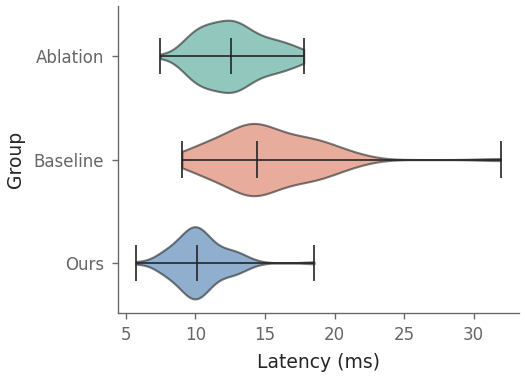

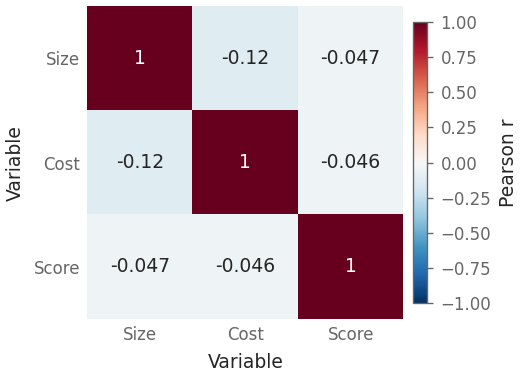

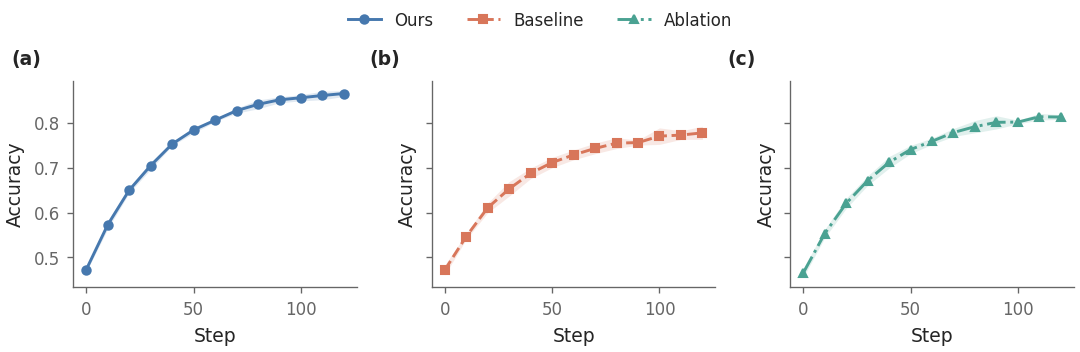

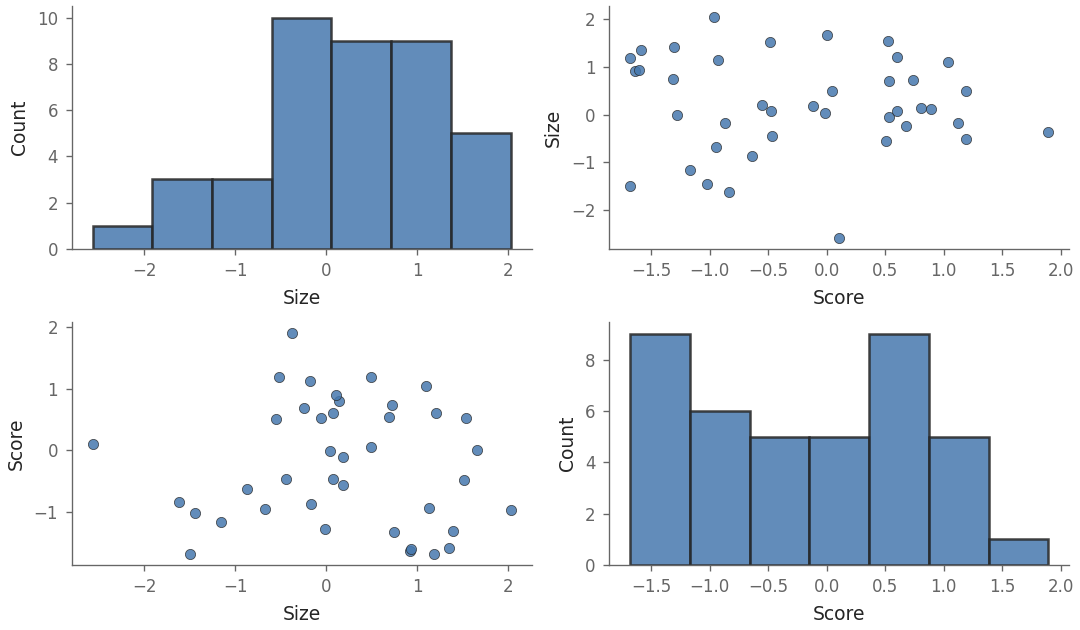

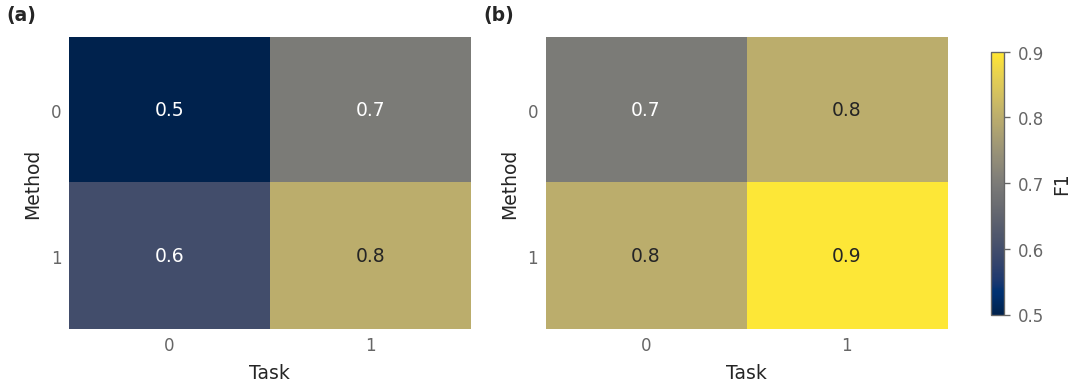

{'size_inches': [3.5, 2.52],
 'semantic_colors': {'Ours': '#4678ae',
  'Baseline': '#d8765a',
  'Ablation': '#4aa292'},
 'exports': [{'path': '/scratch/mingyan_root/mingyan/jmtang/outputs/LLM4Policy/synthetic/rendeer/saturation-refresh/notebook/gallery/line.png',
   'format': 'png',
   'dpi': 300,
   'sha256': '9b0ca402d70b1ce39eaa53cd41c3110596713a6109241fa1b6af54b791dd3aff'}]}

PNG pixels: (1050, 756) | DPI: (299.9994, 299.9994)


In [12]:
gallery = make_gallery()
gallery_dir = OUTPUT / "gallery"
gallery_dir.mkdir(exist_ok=True)
rows = []
for name, fig in gallery.items():
    report = fig.validate()
    assert report.passed, (name, report.to_dict())
    paths = fig.save(gallery_dir / f"{name}.png", overwrite=True)
    rows.append({"example": name, "passed": report.passed,
                 "warnings": len(report.warnings), "png": str(paths[0])})
gallery_table = pd.DataFrame(rows)
display(gallery_table[["example", "passed", "warnings"]])
display(gallery["violin"])
display(gallery["correlation"])
display(gallery["facet"])
display(gallery["pairplot"])
display(gallery["shared_colorbar"])
# Facet caption: (a) Ours, (b) Baseline, (c) Ablation, in first-appearance order.
manifest = json.loads((gallery_dir / "line.json").read_text())
display({"size_inches": manifest["size_inches"], "semantic_colors": manifest["semantic_colors"],
         "exports": manifest["exports"]})
with Image.open(gallery_dir / "line.png") as im:
    print("PNG pixels:", im.size, "| DPI:", im.info["dpi"])


## 11. Run the package regression suite

The test suite includes statistical semantics, layout failures, context isolation, deterministic rendering and exports. This invokes only the self-contained Rendeer package tests. The parent LLM4Policy suite has separate historical module dependencies and is not a prerequisite for plotting.

In [13]:
test_output = OUTPUT / "tests"
test_output.mkdir(exist_ok=True)
command = [
    sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider",
    f"--basetemp={test_output / 'tmp'}", f"--junitxml={test_output / 'pytest.xml'}",
]
result = subprocess.run(command, cwd=PACKAGE, text=True, capture_output=True, check=False)
(test_output / "pytest.log").write_text(result.stdout + result.stderr)
print(result.stdout)
if result.stderr:
    print(result.stderr)
assert result.returncode == 0, f"Tests failed; inspect {test_output / 'pytest.log'}"


.....................................................                    [100%]
53 passed in 18.58s



## 12. Acceptance record

The record below links the real artifacts generated by this execution. PNG is the only figure format emitted by this notebook. The library also accepts an explicitly requested PDF export; this notebook does not request one.

In [14]:
acceptance = {
    "dataset": "synthetic demonstration",
    "seed": 20261013,
    "python": sys.version.split()[0],
    "rendeer": rd.__version__,
    "matplotlib": mpl.__version__,
    "palette": palette_rows,
    "default_method_colors": {name: rd.color_for(name) for name in ["Ours", "Baseline", "Ablation"]},
    "gallery_count": len(gallery),
    "all_gallery_checks_passed": bool(gallery_table["passed"].all()),
    "test_exit_code": result.returncode,
    "gallery_directory": str(gallery_dir),
    "pytest_xml": str(test_output / "pytest.xml"),
    "overview_png": str(OUTPUT / "research_overview.png"),
}
(OUTPUT / "acceptance.json").write_text(json.dumps(acceptance, indent=2) + "\n")
display(acceptance)


{'dataset': 'synthetic demonstration',
 'seed': 20261013,
 'python': '3.12.15',
 'rendeer': '0.1.0',
 'matplotlib': '3.10.8',
 'palette': [{'name': 'Blue',
   'hex': '#4678AE',
   'contrast_on_white': 4.607076623440206},
  {'name': 'Coral', 'hex': '#D8765A', 'contrast_on_white': 3.1537231148278977},
  {'name': 'Teal', 'hex': '#4AA292', 'contrast_on_white': 3.0548271980900776},
  {'name': 'Lavender',
   'hex': '#927BB5',
   'contrast_on_white': 3.6696470642215218},
  {'name': 'Ochre', 'hex': '#B88A44', 'contrast_on_white': 3.107919385160872},
  {'name': 'Rose', 'hex': '#C06C84', 'contrast_on_white': 3.6716451401664996},
  {'name': 'Slate',
   'hex': '#7A8594',
   'contrast_on_white': 3.7432152850659537}],
 'default_method_colors': {'Ours': '#4678ae',
  'Baseline': '#d8765a',
  'Ablation': '#4aa292'},
 'gallery_count': 30,
 'all_gallery_checks_passed': True,
 'test_exit_code': 0,
 'gallery_directory': '/scratch/mingyan_root/mingyan/jmtang/outputs/LLM4Policy/synthetic/rendeer/saturation-r